In [1]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from rasterio.transform import rowcol
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Index(['Refer_dem', 'B1_10_1', 'B2_10_1', 'B3_10_1', 'B4_10_1', 'B1_20_1',
       'B2_20_1', 'B3_20_1', 'B4_20_1', 'B1_30_1',
       ...
       'B3_76_5', 'B4_76_5', 'b1_Morecam', 'b2_Morecam', 'b3_Morecam',
       'b4_Morecam', 'b5_Morecam', 'b6_Morecam', 'b7_Morecam', 'geometry'],
      dtype='object', length=169)

In [1]:
# shp中用于聚合的字段名（例如高程、观测值等）
import geopandas as gpd
import rasterio
from rasterio.transform import rowcol, xy
import pandas as pd
from shapely.geometry import box, Point

year = 2022
tif_path = f"H:/ICESat-2\A_result/UK_DEM_{year}.tif"
# shp_path = f"E:/UK_situ/Shp_data/situ_{year}.shp"
# shp_path = f"E:/UK_situ/Survey/shp_new/topo_2024_.shp"
shp_path = f'E:/UK_situ/Survey/shp_by_year6/topo_{year}_.shp'

# 需要聚合的字段
value_field = "Elevation_"

# 输出              'E:\UK_situ\Survey\shp_by_year6'
out_polygon_shp = f"E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_polygon_{year}_.shp"
out_point_shp = f"E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_centerpoint_{year}_.shp"

# =========================
# 读取栅格
# =========================
with rasterio.open(tif_path) as src:
    transform = src.transform
    raster_crs = src.crs
    width = src.width
    height = src.height

# =========================
# 读取点shp
# =========================
gdf = gpd.read_file(shp_path)

if value_field not in gdf.columns:
    raise ValueError(f"字段 {value_field} 不存在，请检查属性表字段名。")

gdf = gdf[gdf.geometry.notnull()].copy()
gdf = gdf[gdf[value_field].notnull()].copy()

# 坐标系统一
if gdf.crs != raster_crs:
    gdf = gdf.to_crs(raster_crs)

# =========================
# 计算每个点落在哪个30m像元
# =========================
xs = gdf.geometry.x.values
ys = gdf.geometry.y.values
rows, cols = rowcol(transform, xs, ys)

gdf["row"] = rows
gdf["col"] = cols

# 保留落在栅格范围内的点
gdf = gdf[
    (gdf["row"] >= 0) & (gdf["row"] < height) &
    (gdf["col"] >= 0) & (gdf["col"] < width)
].copy()

if len(gdf) == 0:
    raise ValueError("没有点落入 tif 范围内，请检查坐标系和范围。")

# =========================
# 按30m像元聚合统计
# =========================
grouped = (
    gdf.groupby(["row", "col"])[value_field]
    .agg(["mean", "count", "std", "median", "min", "max"])
    .reset_index()
)

# =========================
# 构建30m polygon geometry
# =========================
poly_geoms = []
point_geoms = []

for _, r in grouped.iterrows():
    row = int(r["row"])
    col = int(r["col"])

    # 像元左上角和右下角坐标
    ulx, uly = xy(transform, row, col, offset="ul")
    lrx, lry = xy(transform, row, col, offset="lr")

    # polygon
    poly = box(ulx, lry, lrx, uly)
    poly_geoms.append(poly)

    # 中心点
    cx, cy = xy(transform, row, col, offset="center")
    point_geoms.append(Point(cx, cy))

# polygon shp
gdf_poly = gpd.GeoDataFrame(grouped.copy(), geometry=poly_geoms, crs=raster_crs)

# point shp
gdf_point = gpd.GeoDataFrame(grouped.copy(), geometry=point_geoms, crs=raster_crs)

# =========================
# 字段名缩短（shp字段名最好别太长）
# =========================
gdf_poly = gdf_poly.rename(columns={
    "mean": "mean_val",
    "count": "pt_count",
    "median": "median_v"
})

gdf_point = gdf_point.rename(columns={
    "mean": "mean_val",
    "count": "pt_count",
    "median": "median_v"
})

# =========================
# 输出shp
# =========================
gdf_poly.to_file(out_polygon_shp, driver="ESRI Shapefile", encoding="utf-8")
gdf_point.to_file(out_point_shp, driver="ESRI Shapefile", encoding="utf-8")

print("完成")
print("Polygon shp:", out_polygon_shp)
print("Point shp:", out_point_shp)

完成
Polygon shp: E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_polygon_2022_.shp
Point shp: E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_centerpoint_2022_.shp


In [3]:
import geopandas as gpd
import rasterio

# 路径
point_path = r"E:/UK_situ\Survey\shp_by_year2/topographic_2020.shp"
raster_path = r"G:/ICESat-2\A_result/UK_DEM_2020.tif"
out_path = r"E:\UK_situ\Survey\shp_by_year2\topographic_2020_withDEM.shp"

# 读取点
gdf = gpd.read_file(point_path)

# 打开栅格
with rasterio.open(raster_path) as src:

    # ⚠️ 坐标系对齐（非常关键）
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    # 提取栅格值
    coords = [(x, y) for x, y in zip(gdf.geometry.x, gdf.geometry.y)]
    values = [val[0] for val in src.sample(coords)]

# 写入字段
gdf["DEM"] = values

# 保存
# gdf.to_file(out_path)

print("完成！")

完成！


In [2]:

import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from scipy.stats import gaussian_kde

def draw_validation_plot2(
    refer_name,
    validation_point_path,
    retrieved_DTM_name,
    output_path,
    name,
    xy_lim_range,
    vmax,
    kde_sample_size=5000   # ⭐关键参数
):

    # ======================
    # 1. 读取 + 筛选
    # ======================
    gdf = gpd.read_file(validation_point_path)[[refer_name, retrieved_DTM_name]]

    z = gdf.dropna(subset=[refer_name, retrieved_DTM_name])
    z = z[
        (z[refer_name] != 0) &
        (z[retrieved_DTM_name] != 0) &
        (z[refer_name] < 6) &
        (z[retrieved_DTM_name] > -5)
    ]
    
    z = z[z!=-999]
    z = z[z!=6]
    z = z[z!=0]
    z = z.dropna()


    x = z[refer_name].values
    y = z[retrieved_DTM_name].values

    # ======================
    # 2. 指标
    # ======================
    diff = y - x
    R2 = r2_score(x, y)
    MAE = np.mean(np.abs(diff))
    RMSE = np.sqrt(np.mean(diff**2))
    num = len(x)

    print(f"R²={R2:.3f}, MAE={MAE:.3f}, RMSE={RMSE:.3f}, N={num}")

    # ======================
    # 3. KDE（只用子样本）
    # ======================
    N = len(x)

    if N > kde_sample_size:
        idx_sample = np.random.choice(N, kde_sample_size, replace=False)
    else:
        idx_sample = np.arange(N)

    xy_sample = np.vstack([x[idx_sample], y[idx_sample]])

    kde = gaussian_kde(xy_sample)

    # ⭐ 对所有点计算密度（关键技巧）
    xy_all = np.vstack([x, y])
    z_density = kde(xy_all)

    # ======================
    # 4. 排序（保证视觉效果）
    # ======================
    idx = z_density.argsort()
    x_sorted = x[idx]
    y_sorted = y[idx]
    z_sorted = z_density[idx]

    # ======================
    # 5. 绘图
    # ======================
    fig, ax = plt.subplots()

    sc = ax.scatter(
        x_sorted,
        y_sorted,
        c=z_sorted,
        s=5,
        cmap='Spectral_r',
        vmin=0,
        vmax=vmax
    )

    cbar = plt.colorbar(sc)
    cbar.ax.tick_params(labelsize=14)

    xmin, xmax = xy_lim_range[0], xy_lim_range[1]

    # 1:1线
    ax.plot([xmin, xmax], [xmin, xmax], '--', color='gray', linewidth=0.8)

    # 文本
    textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"
    ax.text(0.52, 0.05, textstr, transform=ax.transAxes, fontsize=20)
    ax.text(0.05, 0.95, name, transform=ax.transAxes, fontsize=20)

    # 坐标轴
    ax.set_xlabel('Airborne LiDAR DEM', fontsize=18)
    ax.set_ylabel('Retrieved DEM', fontsize=18)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(xmin, xmax)

    ticks = np.arange(xmin, xmax + xy_lim_range[2], xy_lim_range[2])
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(labelsize=16)

    plt.show()
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')
    # plt.close()

    print("绘图完成！")
 
def sample_raster_to_gdf(validation_point_path, raster_path, column_name):
    
    gdf = gpd.read_file(validation_point_path)

    with rasterio.open(raster_path) as src:
        if gdf.crs != src.crs:
            gdf = gdf.to_crs(src.crs)
        coords = [(point.x, point.y) for point in gdf.geometry]
        values = [v[0] if v else None for v in src.sample(coords)]
        gdf[column_name] = values
        
    gdf.to_file(validation_point_path)
    return gdf

In [ ]:

point_path = r"E:/UK_situ\Survey\shp_by_year2/topographic_2023.shp"
raster_path = r"G:/ICESat-2\A_result/UK_DEM_2023.tif"
# out_path = r"E:\UK_situ\Survey\shp_by_year2\topographic_2020_withDEM.shp"
sample_raster_to_gdf(point_path, raster_path, 'DEM')

In [56]:
validation_sample_path = 'E:/UK_situ/situ_2019.shp'
gdf = gpd.read_file(validation_sample_path)
gdf.columns

Index(['Elevation_', 'year', 'Profile', 'Elevation', 'ref_dem', 'DEM',
       'geometry'],
      dtype='object')

In [ ]:
import os
import re
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# 输入/输出路径
input_folder = r"E:\UK_situ\Survey\shp_new\cco_data-20260331074653\data\topographic"
output_folder = r"E:/UK_situ/Survey/shp_new"

import os
import re
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import chardet  # 导入用于检测编码的库


os.makedirs(output_folder, exist_ok=True)

year_dict = {}

# ======================
# 遍历所有txt
# ======================
for file in os.listdir(input_folder):
    if not file.endswith(".txt"):
        continue

    file_path = os.path.join(input_folder, file)

    # ======================
    # ✅ 1. 从后往前找8位日期
    # ======================
    matches = re.findall(r'(\d{8})', file)
    if matches:
        date_str = matches[-1]   # 取最后一个日期
        year = date_str[:4]
    else:
        print(f"跳过（无日期）: {file}")
        continue

    # ======================
    # ✅ 2. 读取数据 (核心修改部分)
    # ======================
    df = None
    
    # 第一步：自动检测文件编码
    try:
        with open(file_path, 'rb') as f:
            # 读取文件前100KB进行编码检测
            result = chardet.detect(f.read(100000))
            detected_encoding = result['encoding']
            # 如果检测置信度太低，默认回退到 utf-8 或 gbk，这里直接用检测到的结果尝试
            print(f"检测到文件 {file} 编码: {detected_encoding} (置信度: {result['confidence']:.2f})")
    except Exception as e:
        print(f"编码检测失败 {file}: {e}")
        detected_encoding = 'utf-8' # 兜底编码

    # 第二步：尝试读取数据
    # 使用 on_bad_lines='skip' 跳过格式错误的行（解决 ParserError）
    # 使用 engine='python' 提高对复杂格式的兼容性
    try:
        df = pd.read_csv(file_path, sep="\t", encoding=detected_encoding, on_bad_lines='skip', engine='python')
    except Exception as e:
        print(f"使用 {detected_encoding} 读取失败，尝试 latin-1: {e}")
        # 如果检测的编码不行，尝试兼容性最强的 latin-1
        try:
            df = pd.read_csv(file_path, sep="\t", encoding='latin-1', on_bad_lines='skip', engine='python')
        except Exception as e2:
            print(f"读取失败 {file}: {e2}")
            continue

    # 如果读取失败或数据为空，跳过该文件
    if df is None or df.empty:
        print(f"跳过（无数据）: {file}")
        continue

    # 清理列名（去除首尾空格）
    df.columns = df.columns.str.strip()

    # ======================
    # ✅ 3. 自动识别字段名
    # ======================
    # 统一小写方便匹配
    col_map = {col.lower(): col for col in df.columns}

    # Easting
    if "easting" in col_map:
        east_col = col_map["easting"]
    elif "eastings" in col_map:
        east_col = col_map["eastings"]
    else:
        print(f"缺少Easting字段: {file}")
        continue

    # Northing
    if "northing" in col_map:
        north_col = col_map["northing"]
    elif "northings" in col_map:
        north_col = col_map["northings"]
    else:
        print(f"缺少Northing字段: {file}")
        continue

    # ======================
    # ✅ 4. 创建点
    # ======================
    # 确保坐标列是数值类型，防止读取时混入字符串导致报错
    df[east_col] = pd.to_numeric(df[east_col], errors='coerce')
    df[north_col] = pd.to_numeric(df[north_col], errors='coerce')
    
    # 删除坐标为空的行
    df.dropna(subset=[east_col, north_col], inplace=True)
    
    if df.empty:
        print(f"跳过（无有效坐标）: {file}")
        continue

    geometry = [Point(xy) for xy in zip(df[east_col], df[north_col])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry)

    # 添加信息
    gdf["source_fil"] = file[:12]   # shp字段≤10字符
    gdf["year"] = year

    # ======================
    # ✅ 5. 存入字典
    # ======================
    if year not in year_dict:
        year_dict[year] = []

    year_dict[year].append(gdf)

# ======================
# 合并并导出
# ======================
for year, gdf_list in year_dict.items():
    print(f"处理年份: {year}, 文件数: {len(gdf_list)}")

    merged_gdf = pd.concat(gdf_list, ignore_index=True)
    merged_gdf = gpd.GeoDataFrame(merged_gdf, geometry="geometry")

    # 设置CRS（UK OSGB36）
    merged_gdf.set_crs(epsg=27700, inplace=True)

    # 防止字段过长（shp限制10字符）
    # 注意：这里直接截断列名，如果前10个字符重复可能会导致合并冲突，需注意
    merged_gdf.columns = [col[:12] for col in merged_gdf.columns]

    out_path = os.path.join(output_folder, f"topo_{year}_.shp")
    merged_gdf.to_file(out_path)

print("全部完成！")

In [31]:
path1 = 'E:/UK_situ/Survey/shp_by_year2/topographic_2019.shp'
path2 = 'E:/UK_situ/Survey/shp_by_year4/topo_2019.shp'
path3 = 'E:/UK_situ/Survey/shp_by_year5/topo_2019.shp'
path4 = 'E:/UK_situ/Survey/shp_by_year6/topo_2019.shp'

a = gpd.read_file(path4)
a.shape

(2306571, 12)

In [190]:
import geopandas as gpd
import pandas as pd

# 输入路径
year = 2024
paths = [
    f'E:/UK_situ/Survey/shp_by_year2/topographic_{year}.shp',
    # f'E:/UK_situ/Survey/shp_by_year4/topo_{year}.shp',
    # f'E:/UK_situ/Survey/shp_by_year5/topo_{year}.shp',
    # 'E:/UK_situ/Survey/shp_by_year6/topo_2019.shp'
]

gdf_list = []

for path in paths:
    gdf = gpd.read_file(path)

    # 🔍 统一字段名（防止大小写/截断问题）
    cols_lower = {col.lower(): col for col in gdf.columns}

    # 匹配字段
    keep_cols = []

    # Elevation_OD（可能被截断为 Elevation_）
    if "elevation_od" in cols_lower:
        keep_cols.append(cols_lower["elevation_od"])
    elif "elevation_" in cols_lower:
        keep_cols.append(cols_lower["elevation_"])

    # Elevation（你反演的）
    if "elevation" in cols_lower:
        keep_cols.append(cols_lower["elevation"])

    # year
    if "year" in cols_lower:
        keep_cols.append(cols_lower["year"])

    # profile（可能大小写不同）
    if "profile" in cols_lower:
        keep_cols.append(cols_lower["profile"])

    # ⚠️ 如果缺字段提示
    if len(keep_cols) < 3:
        print(f"字段不完整: {path}")
        print(gdf.columns)
        continue

    # 保留字段 + geometry
    gdf = gdf[keep_cols + ["geometry"]]

    gdf_list.append(gdf)

# ======================
# 合并
# ======================
merged = pd.concat(gdf_list, ignore_index=True)
merged = gpd.GeoDataFrame(merged, geometry="geometry")

# ======================
# 统一 CRS（以第一个为准）
# ======================
merged.set_crs(gdf_list[0].crs, inplace=True)

# ======================
# 输出
# ======================
# out_path = 'E:/UK_situ/Survey/merged_2019.shp'
# merged.to_file(out_path)

print("合并完成！")

合并完成！


In [192]:
merged

,Elevation_,year,Profile,geometry
0,7.160,2024,DCC09,POINT (303872.636 382790.845)
1,7.373,2024,DCC09,POINT (303872.398 382791.234)
2,7.724,2024,DCC09,POINT (303871.69 382792.532)
3,8.113,2024,DCC09,POINT (303870.624 382794.363)
4,8.444,2024,DCC09,POINT (303869.996 382795.402)
...,...,...,...,...
98999,-0.033,2024,temp_11E01915,POINT (323235.126 563465.877)
99000,-0.087,2024,temp_11E01915,POINT (323238.317 563486.024)
99001,-0.172,2024,temp_11E01915,POINT (323241.459 563505.861)
99002,-0.260,2024,temp_11E01915,POINT (323244.485 563524.97)


In [193]:
# merged['Elevation_'] = pd.to_numeric(merged['Elevation_'], errors='coerce')
# merged['Elevation']  = pd.to_numeric(merged['Elevation'], errors='coerce')

# # 然后再相加，NaN会自动处理
# merged['ref_dem'] = merged[['Elevation_', 'Elevation']].sum(axis=1, skipna=True)
merged['ref_dem']  = merged['Elevation_'] 

In [194]:
yaer = 2024
# out_path = r"E:\UK_situ\Survey\shp_by_year2\topographic_2020_withDEM.shp"
path = f'E:/UK_situ/Survey/shp_new/Topo_{year}_.shp'
raster_path = f"G:/ICESat-2\A_result/UK_DEM_{year}.tif"
# 读取点
gdf = gpd.read_file(path)

# 打开栅格
with rasterio.open(raster_path) as src:

    # ⚠️ 坐标系对齐（非常关键）
    if gdf.crs != src.crs:
        gdf = gdf.to_crs(src.crs)

    # 提取栅格值
    coords = [(x, y) for x, y in zip(gdf.geometry.x, gdf.geometry.y)]
    values = [val[0] for val in src.sample(coords)]

# 写入字段
gdf["DEM"] = values

# 保存
# gdf.to_file(out_path)

print("完成！")

完成！


In [195]:
gdf['ref_DEM'] = pd.to_numeric(gdf['Elevation_'], errors='coerce')

In [196]:
z = gdf.dropna(subset=['ref_DEM', 'DEM'])
z = z[
        (z['ref_DEM'] != 0) &
        (z['DEM'] != 0) &
        (z['ref_DEM'] < 6) &
        (z['DEM'] > -5)
]


In [198]:
z.shape
out_path = 'E:/UK_situ/Survey/shp_new/situ_2024.shp'
z.to_file(out_path)

In [161]:
x = z['ref_DEM'].values
y = z['DEM'].values

    # ======================
    # 2. 指标
    # ======================
diff = y - x
R2 = r2_score(x, y)
MAE = np.mean(np.abs(diff))
RMSE = np.sqrt(np.mean(diff**2))
num = len(x)

print(f"R²={R2:.3f}, MAE={MAE:.3f}, RMSE={RMSE:.3f}, N={num}")

R²=0.648, MAE=0.848, RMSE=1.166, N=1019826


In [3]:
year = 2020
validation_sample_path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}.shp'
a = gpd.read_file(validation_sample_path)
a.columns

Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_202', 'geometry'],
      dtype='object')

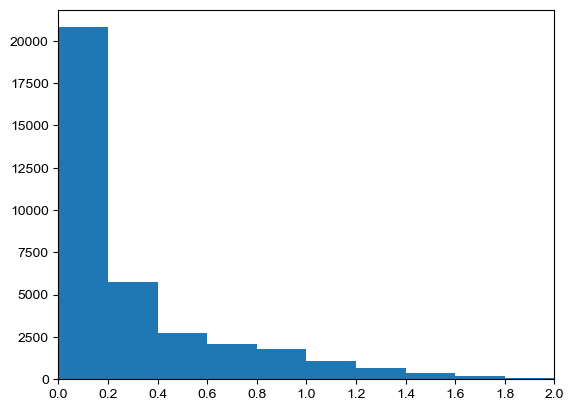

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# 生成边界：0, 0.2, 0.4, ..., 2.0
bins = np.arange(0, 2.1, 0.2)   # 注意终点要包含 2.0，所以用 2.1

plt.hist(a['std'], bins=bins)
plt.xticks(bins)                 # 可选：让 x 轴刻度也显示在每个边界上
plt.xlim(0, 2)
plt.show()

R²=0.676, MAE=0.813, RMSE=1.048, N=10208


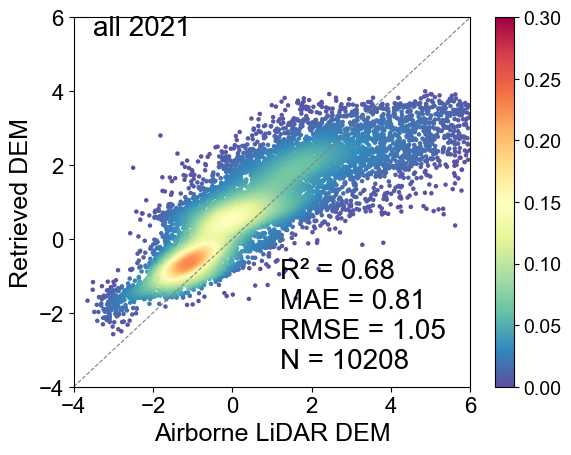

绘图完成！


In [43]:
year = 2021

validation_sample_path = f'E:/UK_situ/Shp_data/profile_agg_30m_centerpoint_{year}.shp'
validation_sample_path = f'E:/UK_situ/Survey/shp_by_year6/profile_agg_30m_centerpoint_{year}.shp'

a = gpd.read_file(validation_sample_path)
a.columns
draw_validation_plot2('median_v' ,validation_sample_path, 'UK_DEM_202', f'E:/UK_situ/all_{year}a.jpg', f'all {year}', [-4, 6, 2], 0.3)

In [5]:
year = 2023
validation_sample_path = f'H:\ICESat-2\Region4_map\Morecambe_map\A2023\A_Morecambe_30m_2023_new10.shp'
a = gpd.read_file(validation_sample_path)
a.columns


Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'LULC', 'geometry'],
      dtype='object')

R²=-0.905, MAE=1.774, RMSE=2.010, N=5401


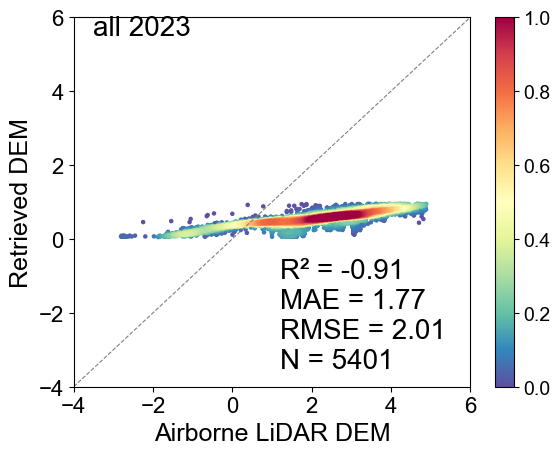

绘图完成！


In [8]:
draw_validation_plot2('OH' ,validation_sample_path, 'b1_FB6', f'E:/UK_situ/all_{year}a.jpg', f'all {year}', [-4, 6, 2], 1)

In [ ]:
a = gpd.read_file()

2023: R² = -0.905, MAE = 1.774, MSB = -1.538, RMSE = 2.010, N = 5401


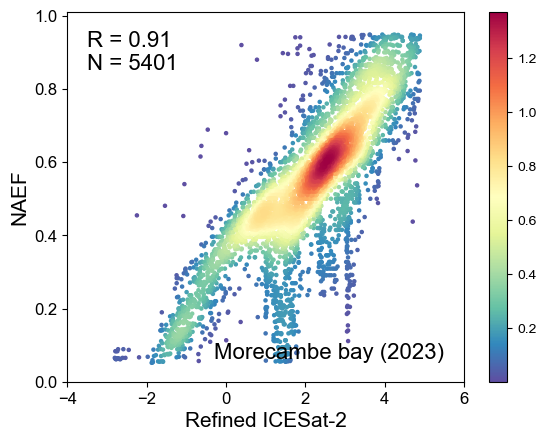

In [39]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score
from scipy.stats import gaussian_kde

# points = gpd.read_file('H:\ICESat-2\Discussion5_1_new\A_Ribble1_30m_2022_new10.shp')
points = gpd.read_file('H:\ICESat-2\Region4_map\Morecambe_map\A2023\A_Morecambe_30m_2023_new10.shp')
# points = gpd.read_file('H:\ICESat-2\Discussion51_new\Validation_point_Thames_new.shp')
points['Refer_dem'] = points['OH']

location2 = 'Morecambe bay'
target_name_list = ['b1_FB6']

for target_name in target_name_list:
    
    z = points[['Refer_dem', target_name]]
    mask = (z[target_name] != 0) | (z['Refer_dem'] != 6) | (z['Refer_dem'] != -999)
    z = z[mask]
    z = z[z != -999]
    z = z[z != 6]
    z = z[z != 0]
    z = z.dropna()
    
    x = np.array(z['Refer_dem'])  # y_true
    y = np.array(z[target_name])  # y_pred
    
    R2 = r2_score(x, y)
    MAE = np.mean(np.abs(y - x))
    MSB = np.mean(y - x)
    RMSE = np.sqrt(np.mean((y - x)**2))
    num = int(len(x))
    
    print(f"{year}: R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")
    
    # 密度计算
    xy = np.vstack([x, y])
    z_density = gaussian_kde(xy)(xy)
    idx = z_density.argsort()
    x_sorted, y_sorted, z_sorted = x[idx], y[idx], z_density[idx]
    
    fig, ax = plt.subplots()
    #textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nMSB = {MSB:.2f}\nN = {num}"
    textstr = f"R = {np.abs(R2):.2f}\nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=16, verticalalignment='top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')
    
    ax.set_xlabel('Refined ICESat-2', fontsize=15)
    ax.set_ylabel('NAEF', fontsize=15)
    
    # 1:1 参考线（可选，因为范围不同，线会陡峭，但很多论文仍保留作为趋势参考）
    # ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    
    sc = ax.scatter(x_sorted, y_sorted, c=z_sorted, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)
    
    # 坐标轴范围
    ax.set_xlim(-2, 2)
    ax.set_ylim(-0, 1.01)
    
    # 刻度
    ax.set_xticks(np.arange(-4, 6.1, 2))
    ax.set_yticks(np.arange(-0, 1.01, 0.2))
    
    # 如果之前有 ax.set_aspect('equal') 请删除或注释，否则图形会被压扁
    # ax.set_aspect('equal')
    
    ax.tick_params(axis='both', labelsize=12)
    
    plt.show()
    plt.close()